In [1]:
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
ticker="^GSPC"
start_date="2006-01-01"
end_date="2026-09-20"

In [3]:
data=yf.download(ticker,start_date,end_date)['Close']
data=pd.DataFrame(data)
data.head()

[*********************100%***********************]  1 of 1 completed


Ticker,^GSPC
Date,
2006-01-03,1268.800049
2006-01-04,1273.459961
2006-01-05,1273.479980
2006-01-06,1285.449951
2006-01-09,1290.150024


In [4]:
# log returns: today vs YESTERDAY (shift(1)
log_ret=np.log(data/data.shift(1)).dropna()
log_ret.head()

Ticker,^GSPC
Date,
2006-01-04,0.003666
2006-01-05,0.000016
2006-01-06,0.009356
2006-01-09,0.003650
2006-01-10,-0.000357


In [9]:
#Outlier calculation and cleaning flag data-entry errors, not real crashes
mean_r, std_r=log_ret.mean(), log_ret.std()
z=(log_ret-mean_r)/std_r
z=z["^GSPC"]
outliers=log_ret[z.abs()>8] #8 Sigma wide on purpose to not exclude 2008/2020 crash.
print(f"Flagged outliers:{len(outliers)}")
log_ret_clean=log_ret[z.abs()<8]
log_ret_clean

Flagged outliers:4


Ticker,^GSPC
Date,
2006-01-04,0.003666
2006-01-05,0.000016
2006-01-06,0.009356
2006-01-09,0.003650
2006-01-10,-0.000357
...,...
2026-09-14,-0.004844
2026-09-15,-0.004505
2026-09-16,-0.004482


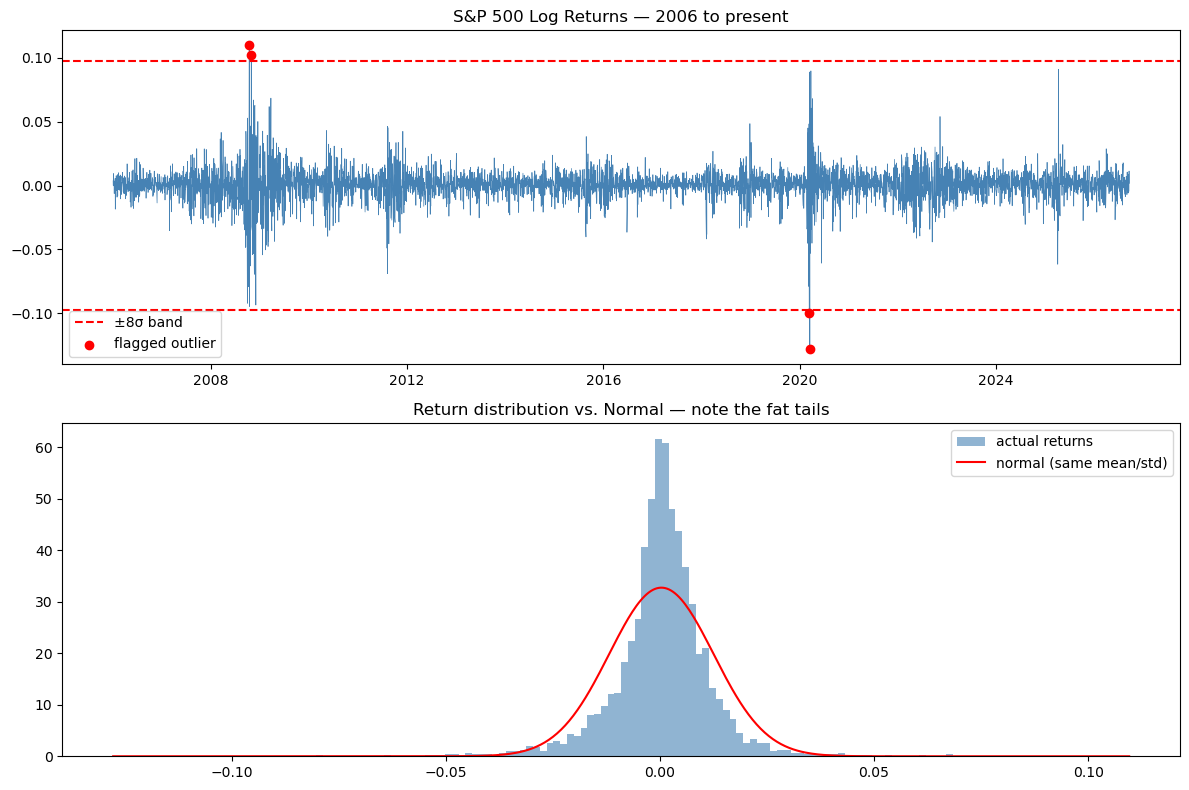

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# 1. Time series with the outlier band
axes[0].plot(log_ret.index, log_ret["^GSPC"], linewidth=0.5, color="steelblue")
axes[0].axhline(mean_r["^GSPC"] + 8*std_r["^GSPC"], color="red", linestyle="--", label="±8σ band")
axes[0].axhline(mean_r["^GSPC"] - 8*std_r["^GSPC"], color="red", linestyle="--")
if len(outliers) > 0:
    axes[0].scatter(outliers.index, outliers["^GSPC"], color="red", zorder=5, label="flagged outlier")
axes[0].set_title("S&P 500 Log Returns — 2006 to present")
axes[0].legend()

# 2. Histogram: return distribution vs. a normal curve with the same mean/std
axes[1].hist(log_ret["^GSPC"], bins=150, density=True, alpha=0.6, color="steelblue", label="actual returns")
x = np.linspace(log_ret["^GSPC"].min(), log_ret["^GSPC"].max(), 500)
from scipy.stats import norm
axes[1].plot(x, norm.pdf(x, mean_r["^GSPC"], std_r["^GSPC"]), color="red", label="normal (same mean/std)")
axes[1].set_title("Return distribution vs. Normal — note the fat tails")
axes[1].legend()

plt.tight_layout()
plt.show()